# BE_ML — Pipeline Copilote

Notebook de restitution. Il **importe les artefacts** produits par `make all`
(`reports/results/*.json`, `reports/figures/*`) et s'exécute de haut en bas
sans réentraîner, à partir du cache vérifié.

Toutes les valeurs numériques affichées proviennent des fichiers de résultats.
Graine `42` ; données brutes en lecture seule.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

RES = Path("reports/results")
FIG = Path("reports/figures")


def load(name):
    return json.loads((RES / name).read_text(encoding="utf-8"))


def show_fig(name, width=720):
    path = FIG / f"{name}.png"
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"figure absente : {path}")

## 1. Chargement et inventaire des données

Lecture tolérante aux lignes irrégulières, tokenisation sans perte.

In [2]:
loading = load("loading.json")
print("train :", loading["train_sessions"], "sessions")
print("test  :", loading["test_sessions"], "sessions")
print("classes :", loading["classes"], "| support min :", loading["min_class_size"])
print("tokens distincts (union) :", loading["distinct_tokens_union"])
print("tokens de contexte imbriqué :", loading["nested_context_tokens"])
print("échecs de reconstruction :", loading["roundtrip_failures"])

train : 3279 sessions
test  : 324 sessions
classes : 247 | support min : 4
tokens distincts (union) : 9651
tokens de contexte imbriqué : 2
échecs de reconstruction : 0


## 2. Analyse exploratoire (EDA)

Statistiques de session, vocabulaires, décalage train/test.

navigateurs (train) : {'Firefox': 1466, 'Google Chrome': 1339, 'Microsoft Edge': 451, 'Opera': 23}
utilisateurs multi-navigateurs : 0
tokens inconnus du test (fraction) : 0.001011
doublons exacts train/test : 0
sessions sans action : {'train': 1, 'test': 0}


- clock : tNN est traité comme un repère en secondes; différences positives et remises à zéro sont des proxys, pas des durées exactes par action.
- browser : Un navigateur constant par utilisateur serait un filtre de candidats, pas un identifiant unique.
- shift : Tests KS descriptifs sans correction multiple; le test sert à décrire le décalage, jamais à ajuster un vocabulaire.
- duplicates : Les doublons exacts et conflits sont comptés avant interprétation des scores; les sessions restent l'unité de validation imposée.

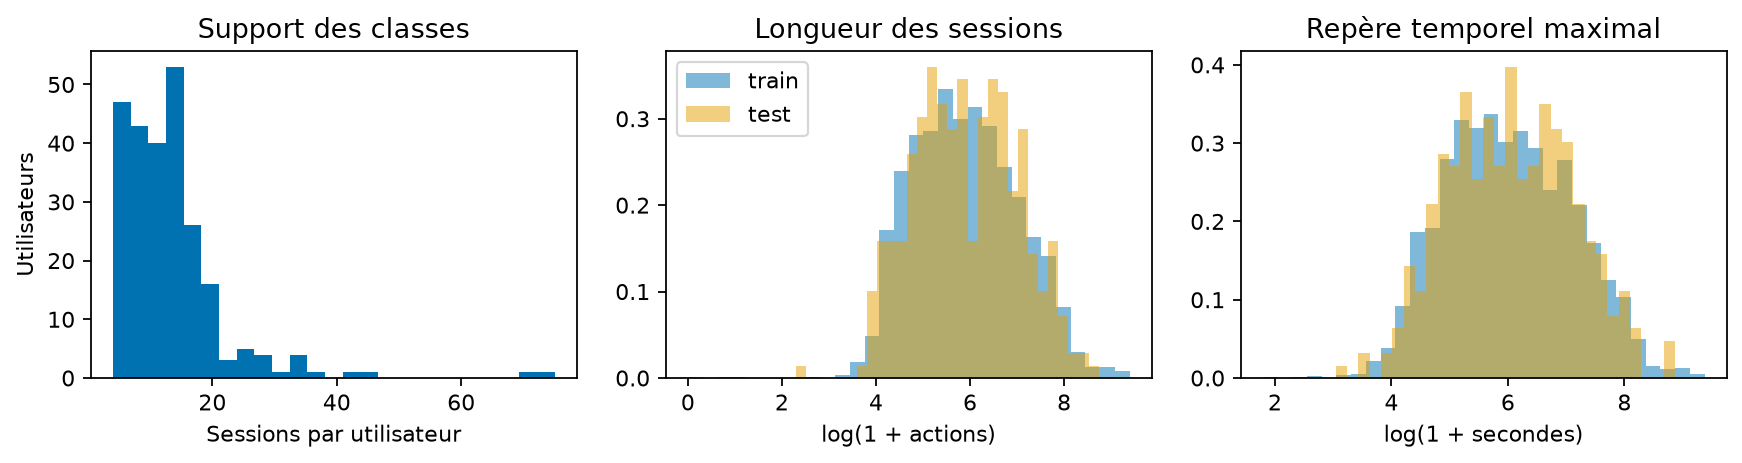

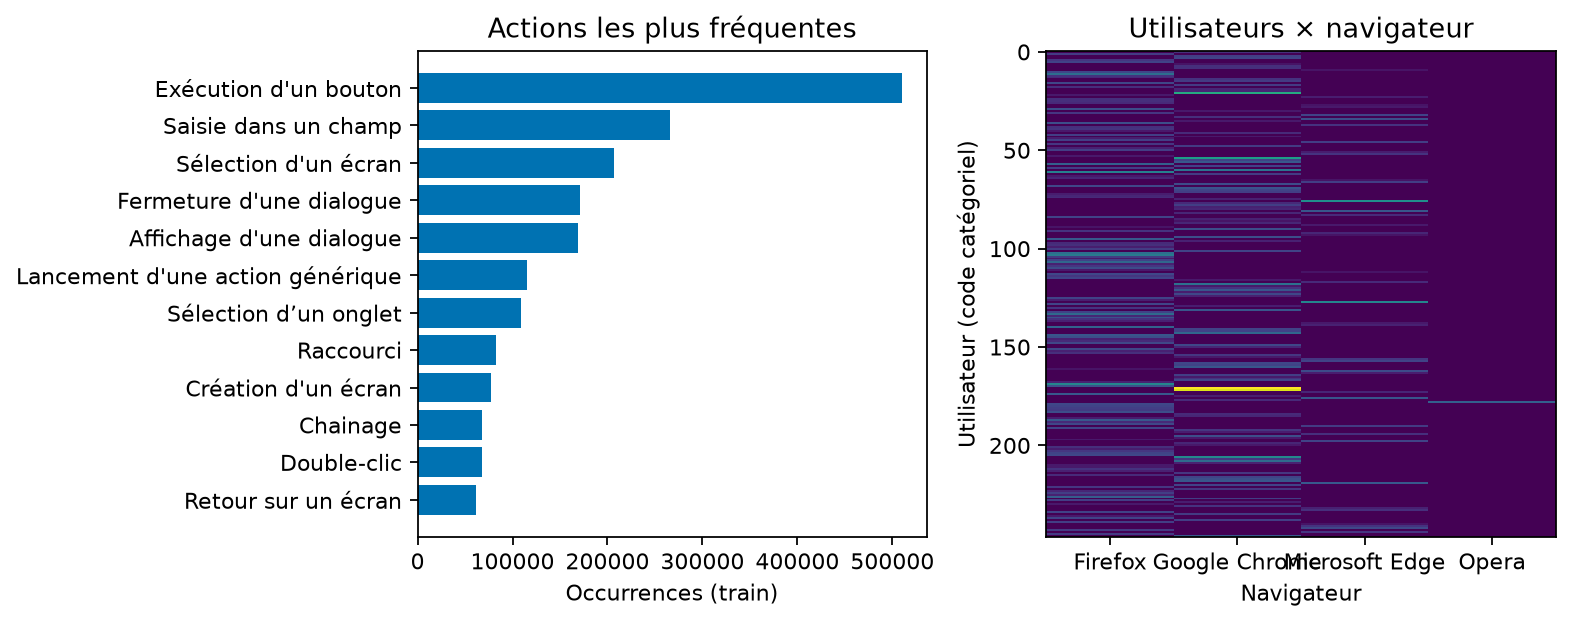

In [3]:
eda = load("eda.json")
print("navigateurs (train) :", eda["browsers"]["train"])
print("utilisateurs multi-navigateurs :", eda["users_with_multiple_browsers"])
print("tokens inconnus du test (fraction) :", round(eda["test_oov_token_fraction"], 6))
print("doublons exacts train/test :", eda["train_test_exact_overlap"])
print("sessions sans action :", eda["zero_action_sessions"])
display(Markdown("\n".join(f"- {k} : {v}" for k, v in eda["interpretation"].items())))
show_fig("eda_overview")
show_fig("eda_actions_browser")

## 3. Caractéristiques et analyses descriptives

Familles de variables construites **dans les plis** (`min_df`, vocabulaires,
scaling appris uniquement sur l'entraînement).

dimension de l'union (train) : [3279, 45140]
matrice creuse : True | densité : 0.005307
variance expliquée SVD(2) : [0.0557, 0.2541]
tests exportés : 19


Codes de classes nominaux, pas de corrélation numérique avec la cible. ANOVA fragile sous asymétrie/hétéroscédasticité; Kruskal et correction de Bonferroni complètent une analyse exploratoire. Les dépendances intra-utilisateur limitent les p-valeurs. La sélection prédictive reste dans les plis.

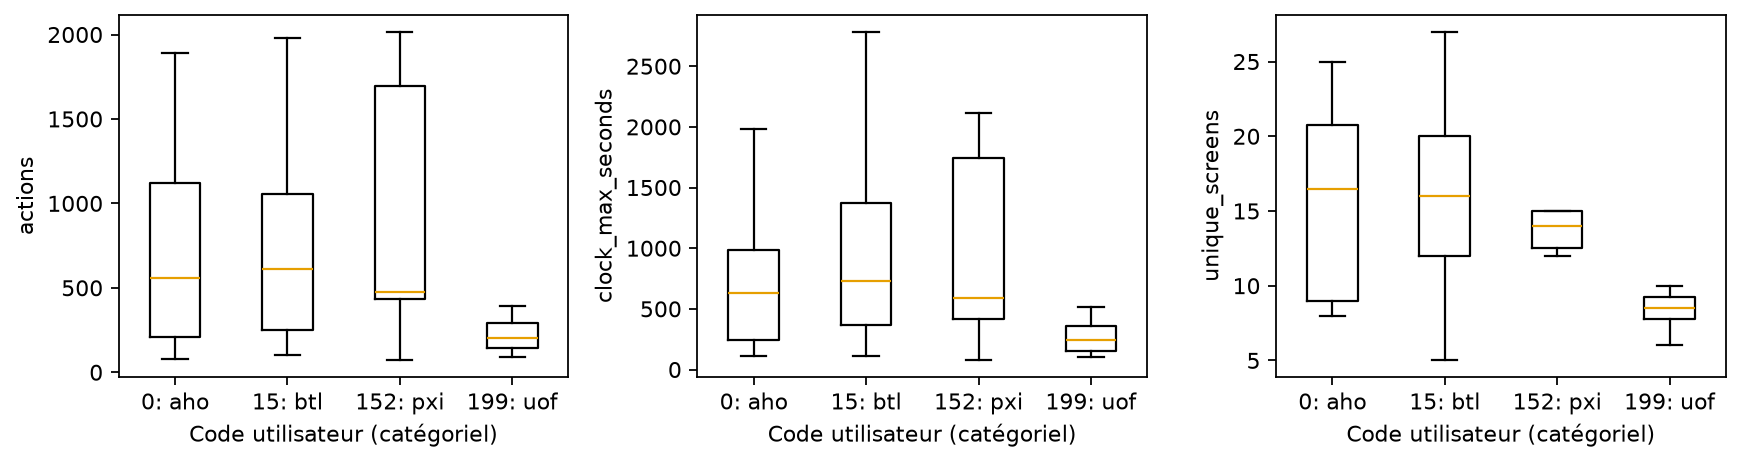

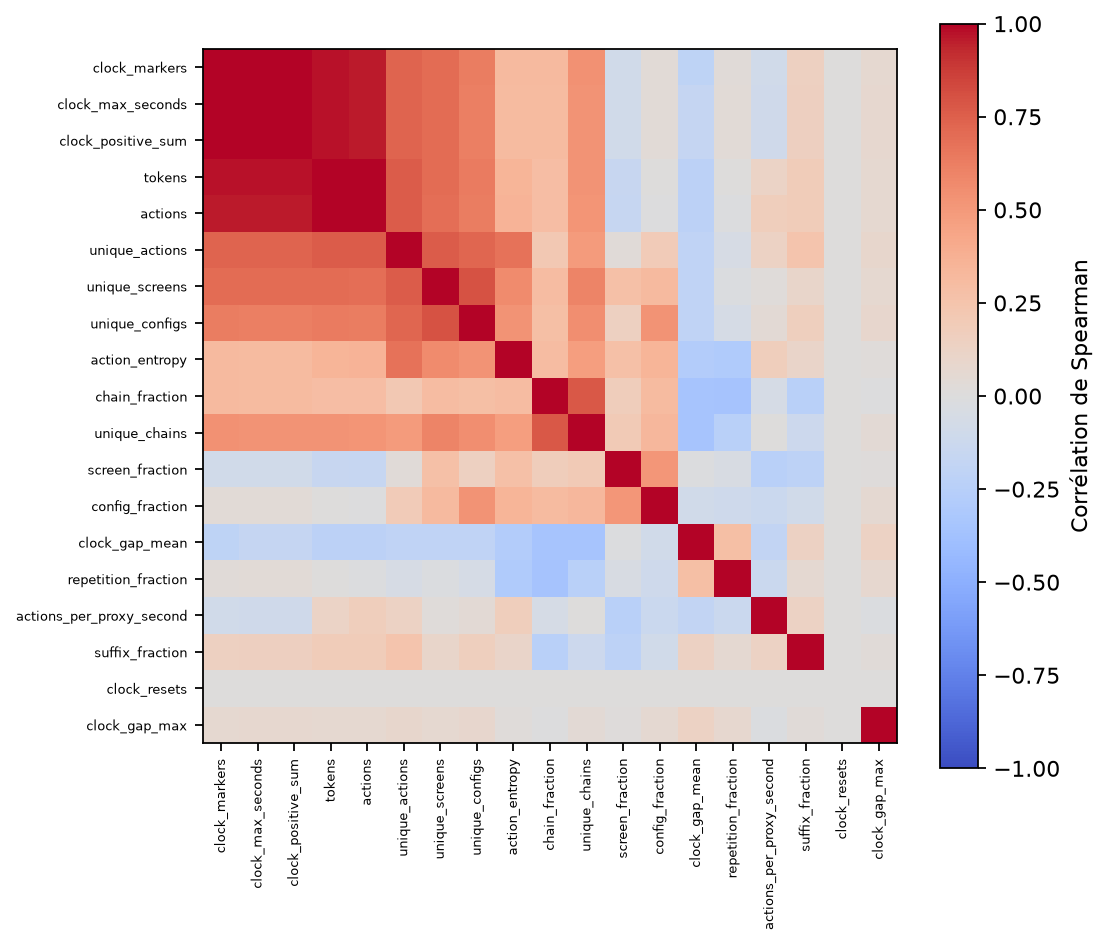

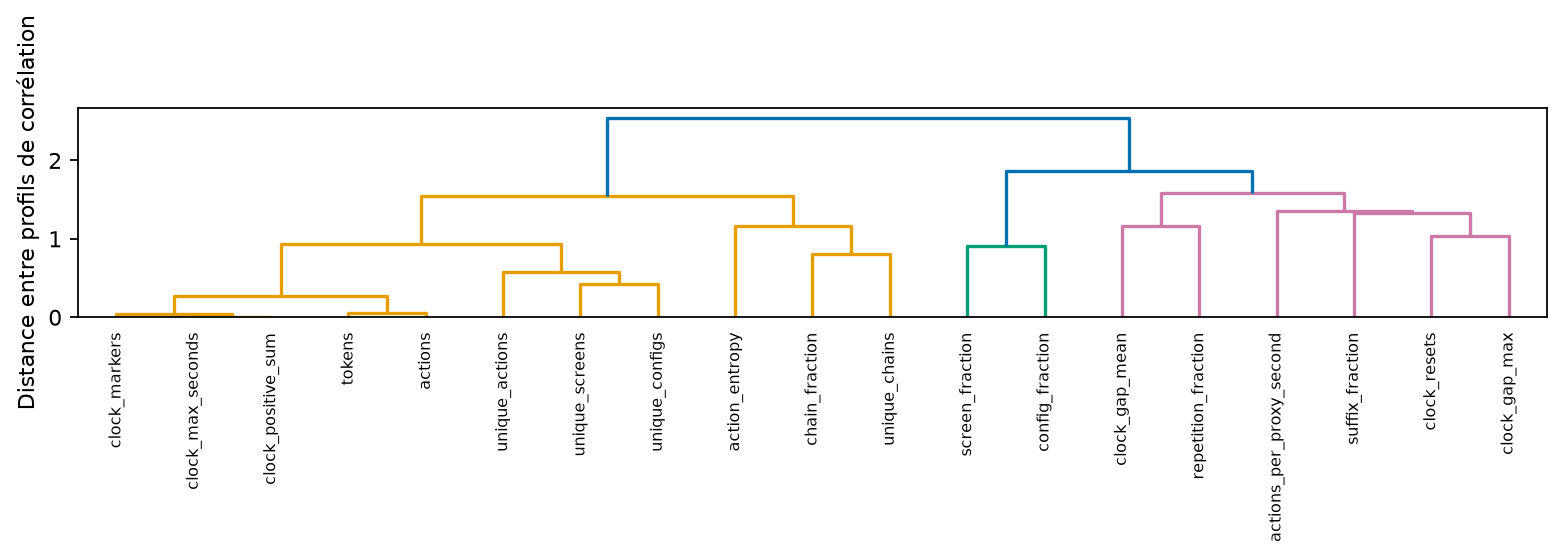

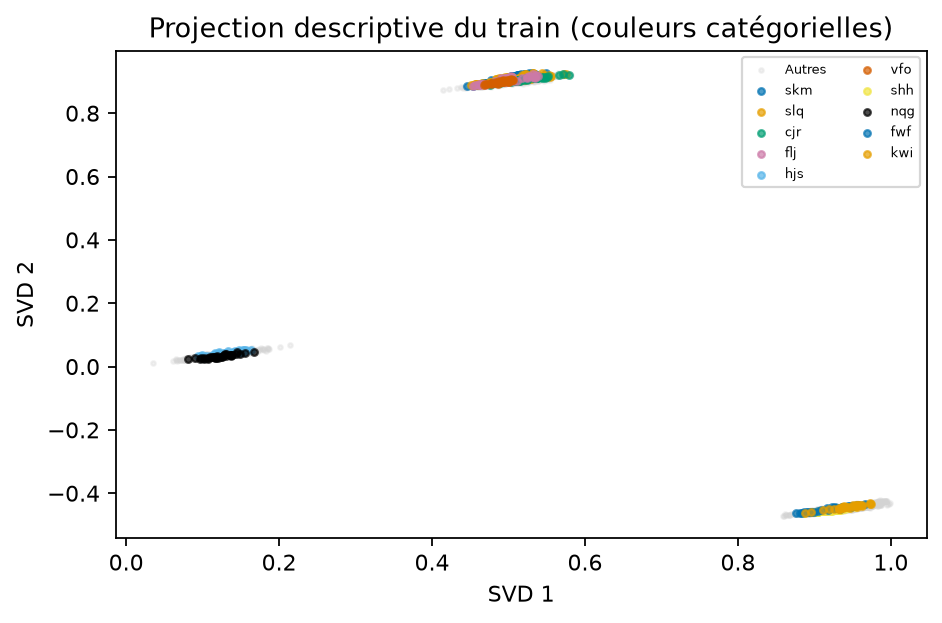

In [4]:
feat = load("features.json")
print("dimension de l'union (train) :", feat["matrix_shape"])
print("matrice creuse :", feat["sparse"], "| densité :", round(feat["density"], 6))
print("variance expliquée SVD(2) :", [round(v, 4) for v in feat["svd_explained_variance"]])
print("tests exportés :", len(feat["tests"]))
display(Markdown(feat["interpretation"]))
for name in ["feature_boxplots", "feature_correlations", "feature_dendrogram", "feature_projection"]:
    show_fig(name)

## 4. Sélection et validation

Une réserve (`holdout`) est mise de côté **avant** toute sélection. Le choix se fait
par validation croisée répétée sur la partie développement ; règle « plus simple à
moins de 1 écart-type », ensemble adopté seulement si le gain dépasse 1 écart-type.

In [5]:
selection = load("selection.json")
print("règle :", selection["selection_rule"])
print("modèle retenu :", selection["selected"])
print("spécification :", selection["spec"])
print("meilleur développement :", selection["best_development_mean"])
print("seuil 1 écart-type :", round(selection["one_std_cutoff"], 4))

holdout = load("holdout.json")
print("\n-- réserve indépendante (20%) --")
for k, v in holdout["metrics"].items():
    print(f"{k:>18} : {v:.4f}")
print("log-loss calibrée :", round(holdout["calibrated_metrics"]["log_loss"], 4),
      "| probabilités :", holdout["probability_kind"])

règle : Simplest predeclared complexity within one std of best single; vote requires gain > selected std. Development 3-fold only.
modèle retenu : linear_balanced
spécification : {'model': 'linear', 'families': ['raw', 'browser'], 'class_weight': 'balanced', 'complexity': 1}
meilleur développement : linear_balanced
seuil 1 écart-type : 0.9274

-- réserve indépendante (20%) --
          accuracy : 0.9512
          macro_f1 : 0.9405
       weighted_f1 : 0.9470
 balanced_accuracy : 0.9466
              top3 : 0.9893
              top5 : 0.9909
          log_loss : 4.1123
log-loss calibrée : 0.3235 | probabilités : uncalibrated_score_softmax


rôle de la VC répétée : Descriptive stability after development selection; not unbiased nested model-selection performance.


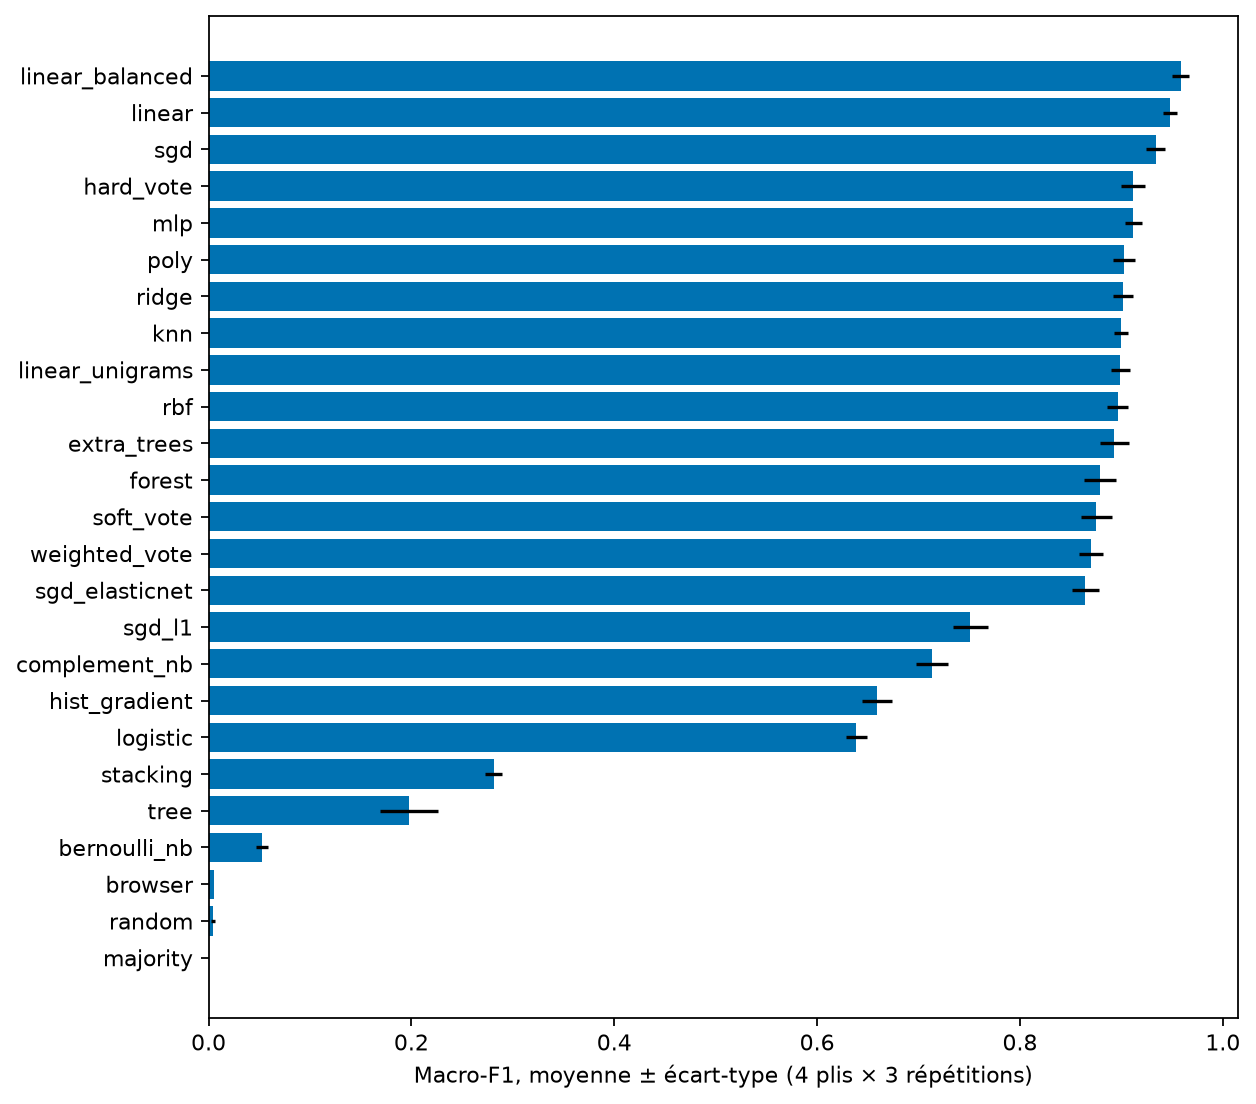

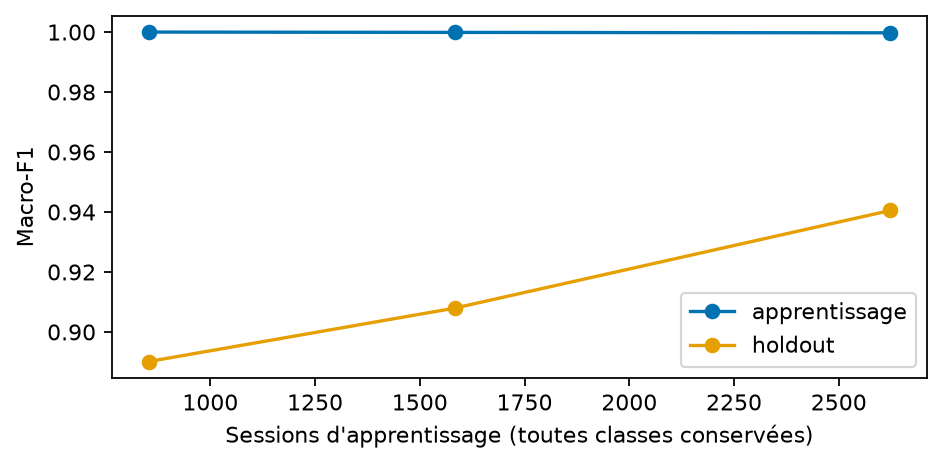

In [6]:
evaluation = load("evaluation.json")
print("rôle de la VC répétée :", evaluation.get("repeated_cv_role", "(non renseigné)"))
show_fig("model_comparison", width=900)
show_fig("learning_curve")

## 5. Interprétabilité

- modèle linéaire : décomposition exacte coefficient × TF-IDF ;
- forêt : décomposition de chemin exacte (attention : **pas** une valeur de Shapley) ;
- importance de familles par permutation groupée.

modèle retenu : linear_balanced
ECE (fiabilité, top-label) : 0.9336
ECE après calibration sigmoïde : 0.1367
paires confondues les plus fréquentes : [{'truth': 'skm', 'prediction': 'slq', 'count': 2}, {'truth': 'akx', 'prediction': 'hvh', 'count': 1}, {'truth': 'ajo', 'prediction': 'szr', 'count': 1}]


**Importance des familles (perte de macro-F1, permutation groupée)**

- `raw` : 0.9333 ± 0.0032
- `browser` : 0.1133 ± 0.0086

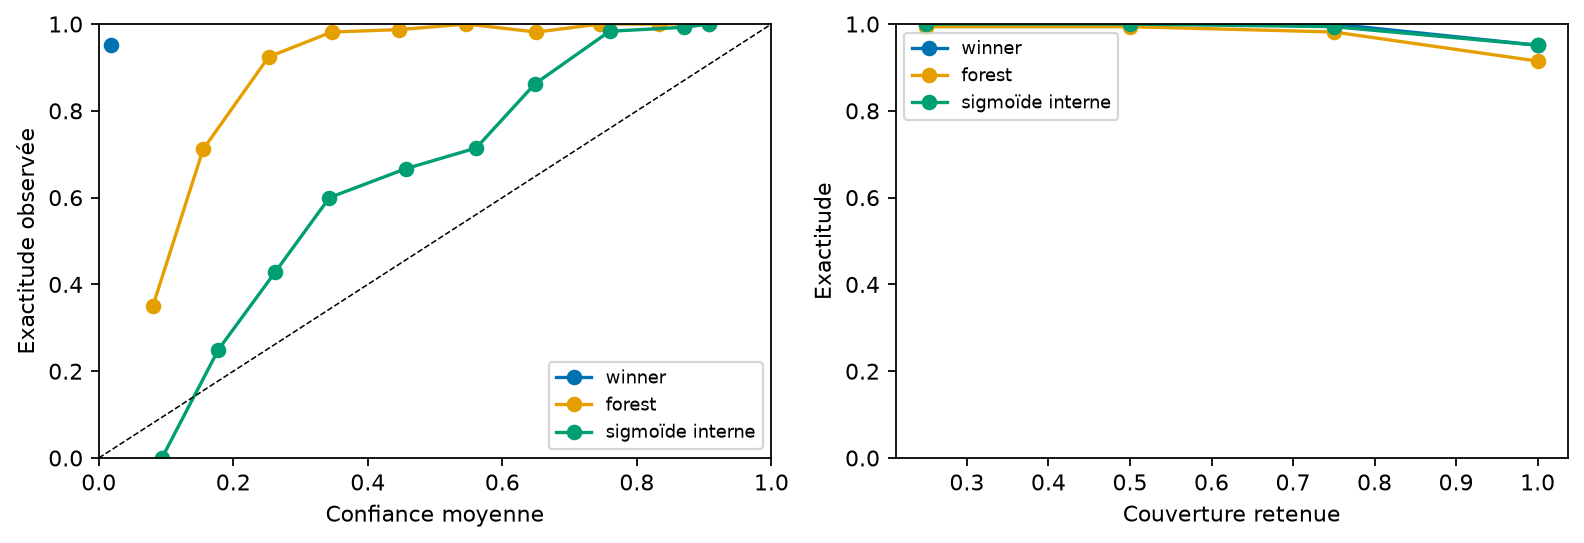

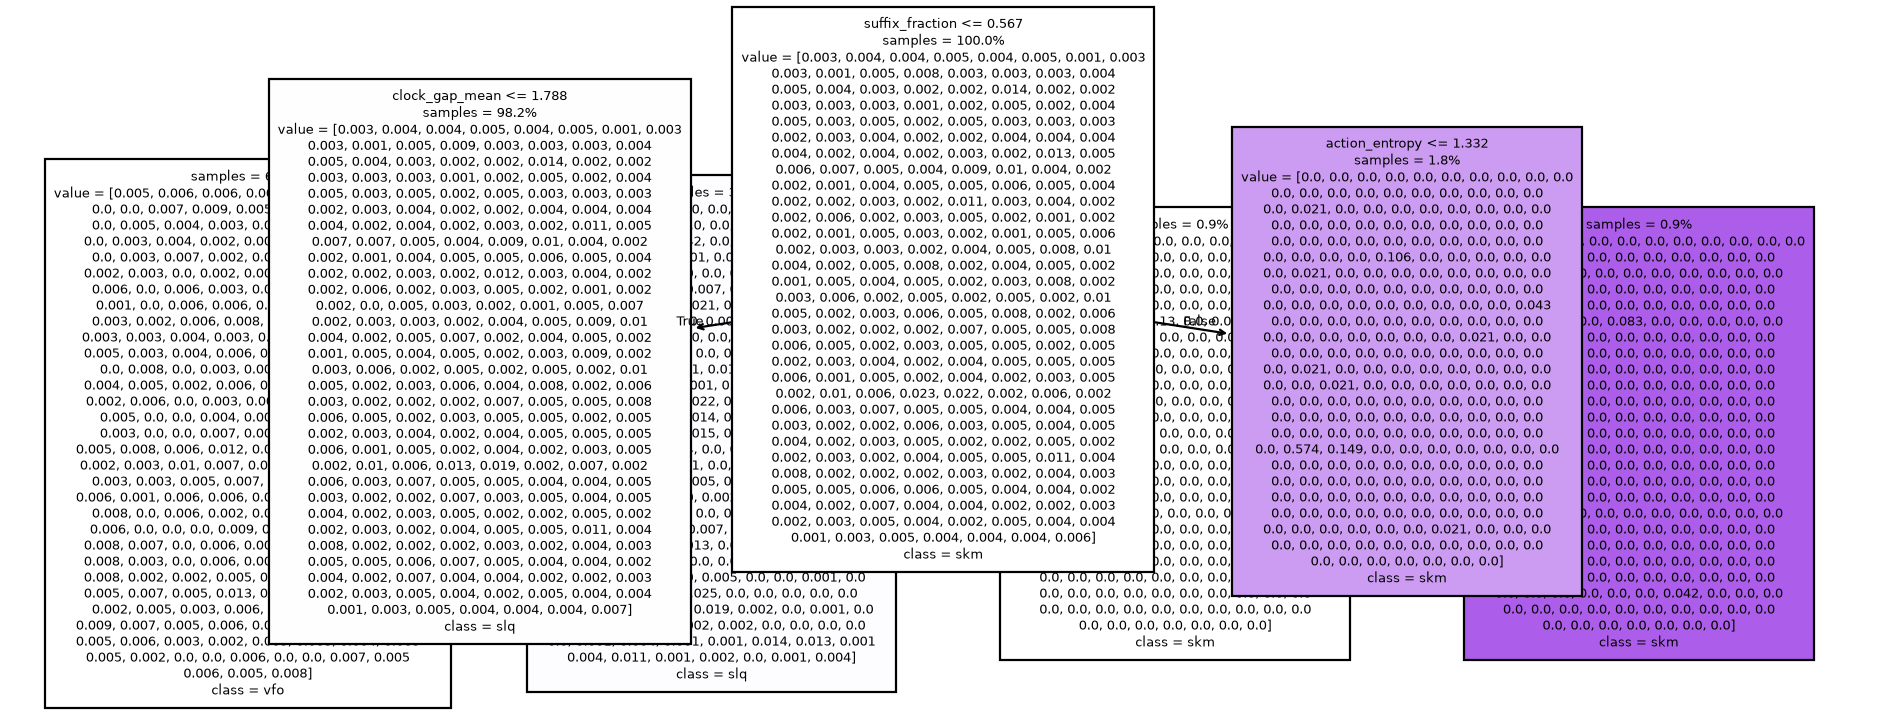

In [7]:
interp = load("interpretability.json")
winner = interp["models"]["winner"]
print("modèle retenu :", interp["selected"])
print("ECE (fiabilité, top-label) :", round(winner["calibration"]["ece"], 4))
print("ECE après calibration sigmoïde :", round(interp["calibrated"]["ece"], 4))
print("paires confondues les plus fréquentes :", winner["confusion_pairs"][:3])

rows = winner.get("grouped_permutation", [])
if rows:
    md = ["**Importance des familles (perte de macro-F1, permutation groupée)**\n"]
    for row in rows:
        md.append(f"- `{row['family']}` : {row['macro_f1_loss_mean']:.4f} ± {row['std']:.4f}")
    display(Markdown("\n".join(md)))
show_fig("confidence")
show_fig("pruned_tree")

## 6. Soumission

Réentraînement final sur l'ensemble d'entraînement, prédiction du test,
validation du format.

In [8]:
sub = load("submission.json")
print("fichier :", sub["submission"])
print("lignes :", sub["rows"], "| format validé :", sub["validated"])
print("transductif :", sub.get("transductive"))
print("sha256 :", sub["submission_sha256"][:16], "...")

fichier : submissions/submission_20261013T192402Z_linear_balanced.csv
lignes : 324 | format validé : True
transductif : False
sha256 : 3ff5121962f6691d ...


## 7. Votre analyse ici

**Question.** Quelle est la variable cachée à prédire, et le signal est-il simple ?

**Réponse.** La cible est la variable de regroupement des sessions par utilisateur
(classes fortement déséquilibrées). Le signal est surtout porté par le
**vocabulaire d'action** (`raw`) et par le **navigateur** (`browser`).

**Observations mesurées** (issues des artefacts) :

- Le contexte (écrans, configurations, chaînes) est **nécessaire** : le retirer fait
  chuter la macro-F1 d'environ 0,94 à ~0,78.
- Ajouter des variables numériques/temps **dégrade** légèrement le modèle linéaire
  (`all` < `linear`) : le bruit temporel nuit.
- Un classifieur **linéaire** régularisé, avec pondération de classes, suffit ;
  les ensembles (voting/stacking) n'apportent pas de gain au-delà d'un écart-type,
  ils ne sont donc pas retenus.
- La réserve indépendante confirme la performance de développement, et la
  **calibration sigmoïde** améliore nettement la log-loss, mais ne sert qu'à la
  confiance affichée.

**Limites honnêtes** : horodatage `tNN` interprété en secondes de façon approximative ;
les statistiques de session supposent des incréments et des remises à zéro
après déconnexion ; la VC répétée complète est **descriptive** et non une estimation
imbriquée non biaisée ; aucune étiquette de test n'a été consultée.